In [1]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['TARGET'] = diabetes.target  # Adăugăm variabila țintă în tabel

print("Primele 5 rânduri din setul de date:")
display(df.head()) # Folosim display() pentru formatare frumoasă în Jupyter/PyCharm Scientific

print("\nCaracteristicile disponibile (feature_names) sunt:")
print(diabetes.feature_names)

Primele 5 rânduri din setul de date:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,TARGET
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Caracteristicile disponibile (feature_names) sunt:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [2]:
print("Informații statistice ale setului de date:")
display(df.describe())

Informații statistice ale setului de date:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,TARGET
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


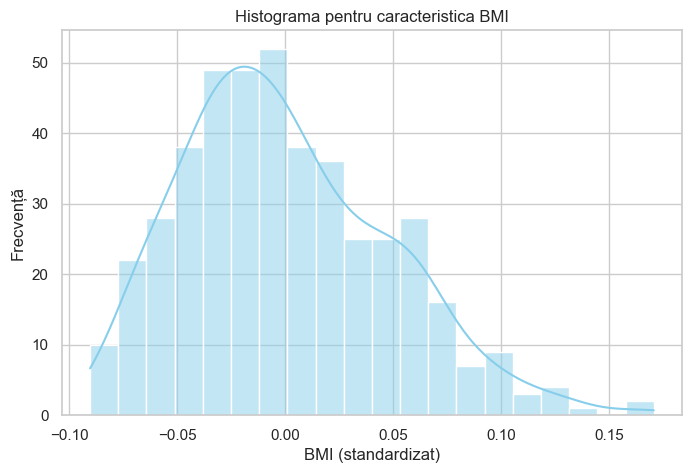

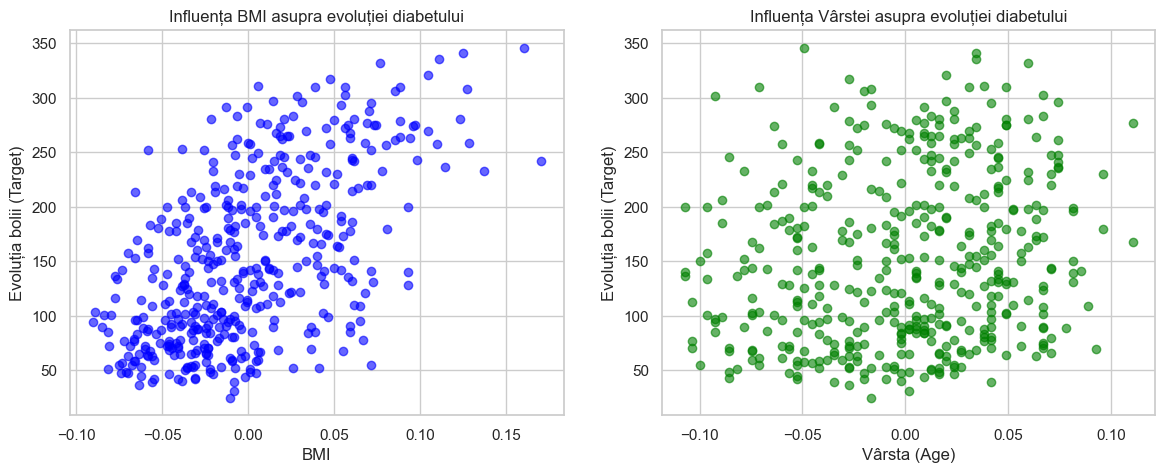

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df['bmi'], bins=20, kde=True, color="skyblue")
plt.title('Histograma pentru caracteristica BMI')
plt.xlabel('BMI (standardizat)')
plt.ylabel('Frecvență')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['bmi'], df['TARGET'], alpha=0.6, color='blue')
axes[0].set_title('Influența BMI asupra evoluției diabetului')
axes[0].set_xlabel('BMI')
axes[0].set_ylabel('Evoluția bolii (Target)')

axes[1].scatter(df['age'], df['TARGET'], alpha=0.6, color='green')
axes[1].set_title('Influența Vârstei asupra evoluției diabetului')
axes[1].set_xlabel('Vârsta (Age)')
axes[1].set_ylabel('Evoluția bolii (Target)')

plt.show()

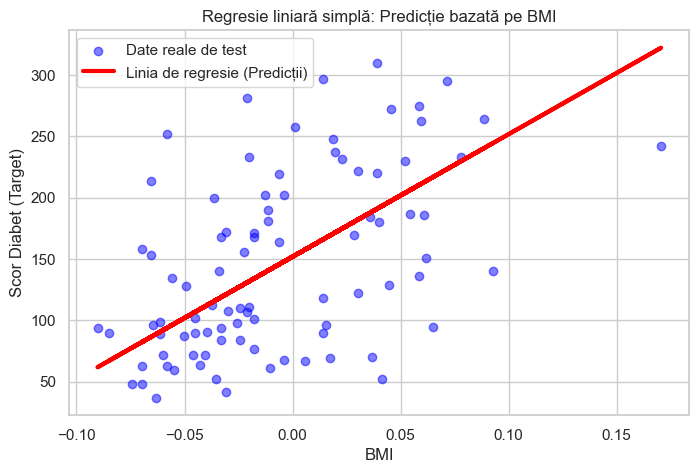

Eroarea pătratică medie (MSE) pentru modelul simplu: 4061.83


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X_simplu = df[['bmi']]
y = df['TARGET']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simplu, y, test_size=0.2, random_state=42)

model_simplu = LinearRegression()
model_simplu.fit(X_train_s, y_train_s)

y_pred_s = model_simplu.predict(X_test_s)

plt.figure(figsize=(8, 5))
plt.scatter(X_test_s, y_test_s, color='blue', alpha=0.5, label='Date reale de test')
plt.plot(X_test_s, y_pred_s, color='red', linewidth=3, label='Linia de regresie (Predicții)')
plt.title('Regresie liniară simplă: Predicție bazată pe BMI')
plt.xlabel('BMI')
plt.ylabel('Scor Diabet (Target)')
plt.legend()
plt.show()

mse_simplu = mean_squared_error(y_test_s, y_pred_s)
print(f"Eroarea pătratică medie (MSE) pentru modelul simplu: {mse_simplu:.2f}")

In [9]:
from sklearn.metrics import r2_score
X_multi = df[['bmi', 'bp']]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

print("--- Coeficienții modelului de regresie multiplă ---")
print(f"Coeficient pentru BMI (m1): {model_multi.coef_[0]:.2f}")
print(f"Coeficient pentru Blood Pressure - bp (m2): {model_multi.coef_[1]:.2f}")
print(f"Intercept (b - unde linia taie axa Y): {model_multi.intercept_:.2f}\n")

r2_multi = r2_score(y_test_m, y_pred_m)
mse_multi = mean_squared_error(y_test_m, y_pred_m)

print(f"Scorul R² pe setul de testare: {r2_multi:.4f}")
print(f"MSE pe setul de testare (pentru comparație): {mse_multi:.2f}")

--- Coeficienții modelului de regresie multiplă ---
Coeficient pentru BMI (m1): 839.52
Coeficient pentru Blood Pressure - bp (m2): 393.45
Intercept (b - unde linia taie axa Y): 151.82

Scorul R² pe setul de testare: 0.2940
MSE pe setul de testare (pentru comparație): 3740.51
